# E-mail campaign A/B test and uplift targeting

Walk-through of the analysis behind `README.md`. Every number is computed live from the DuckDB database built by `src/run_pipeline.py`.

In [1]:
import os, sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, data, experiment
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
results = json.loads(config.RESULTS_JSON.read_text())
df = experiment.add_dummies(data.load_campaign())
df.head()

,customer_id,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,arm,visit,conversion,spend,zip_urban,zip_suburban,zip_rural,channel_web,channel_phone,channel_multichannel
0,1,10,2) $100 - $200,142.4400,1,0,Suburban,0,Phone,Womens E-Mail,Womens,0,0,0.0000,0,1,0,0,1,0
1,2,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,Control,0,0,0.0000,0,0,1,1,0,0
2,3,7,2) $100 - $200,180.6500,0,1,Suburban,1,Web,Womens E-Mail,Womens,0,0,0.0000,0,1,0,1,0,0
3,4,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,Mens,0,0,0.0000,0,0,1,1,0,0
4,5,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,Womens,0,0,0.0000,1,0,0,1,0,0


## 1. Data quality
Hard rules stop the pipeline; soft rules are logged.

In [2]:
data.build_database()

,rule,severity,failures
0,"row count equals 64,000",hard,0
1,no missing values in any column,hard,0
2,arm is one of Mens / Womens / Control,hard,0
3,binary flags are 0 or 1,hard,0
4,recency between 1 and 12 months,hard,0
5,spend is not negative,hard,0
6,spend > 0 only when converted,soft,0
7,converted customers have spend > 0,soft,0
8,conversion only after a visit,soft,0
9,customer bought mens or womens last year,soft,0


## 2. Did the randomization work?

In [3]:
counts = df.arm.value_counts().to_dict()
print(experiment.srm_test(counts))
experiment.smd_table(df).pivot(index='covariate', columns='arm', values='smd')

{'counts': {'Womens': 21387, 'Mens': 21307, 'Control': 21306}, 'chi2': 0.20253125000000002, 'p_value': 0.9036929575604196}


arm,Mens,Womens
covariate,,
channel_multichannel,-0.0042,-0.0053
channel_phone,-0.0083,0.0086
channel_web,0.0110,-0.0051
history,0.0076,0.0065
mens,-0.0046,-0.0086
newbie,-0.0009,0.0026
recency,0.0068,0.0052
womens,0.0076,0.0049
zip_rural,0.0137,0.0040


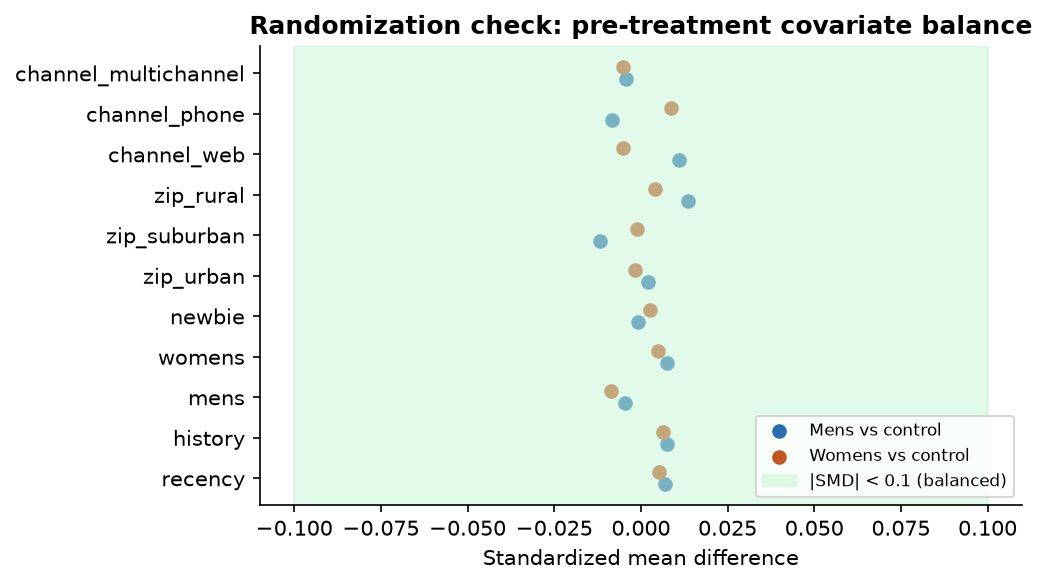

In [4]:
display(Image(filename='reports/figures/02_covariate_balance.png'))

## 3. Treatment effects
Two-proportion tests (visit, conversion), Welch test (spend), bootstrap CIs, Holm correction.

In [5]:
ate = experiment.ate_table(df)
ate[['arm', 'outcome', 'control', 'treated', 'diff', 'ci_low', 'ci_high', 'rel_lift', 'p_value', 'p_holm']]

,arm,outcome,control,treated,diff,ci_low,ci_high,rel_lift,p_value,p_holm
0,Mens,visit,0.1062,0.1828,0.0766,0.0700,0.0832,0.7214,0.0000,0.0000
1,Mens,conversion,0.0057,0.0125,0.0068,0.0050,0.0086,1.1884,0.0000,0.0000
2,Mens,spend,0.6528,1.4226,0.7698,0.4851,1.0545,1.1793,0.0000,0.0000
3,Womens,visit,0.1062,0.1514,0.0452,0.0389,0.0516,0.4261,0.0000,0.0000
4,Womens,conversion,0.0057,0.0088,0.0031,0.0015,0.0047,0.5433,0.0002,0.0003
5,Womens,spend,0.6528,1.0772,0.4244,0.1690,0.6799,0.6502,0.0011,0.0011


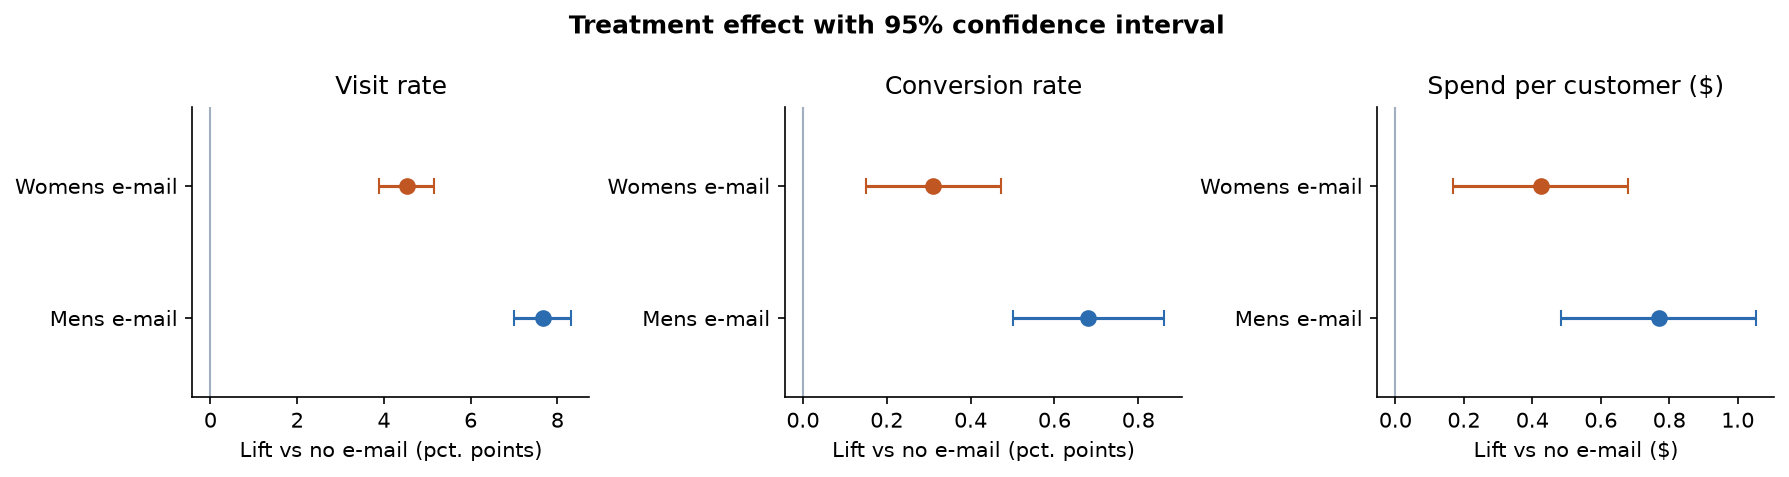

In [6]:
display(Image(filename='reports/figures/01_lift_with_ci.png'))

## 4. Variance reduction checks: CUPED and regression adjustment

In [7]:
pd.concat([experiment.cuped(df, o) for o in config.OUTCOMES])

,arm,outcome,theta,diff_raw,se_raw,diff_cuped,se_cuped,ci_low_cuped,ci_high_cuped,variance_reduction
0,Mens,visit,0.0001,0.0766,0.0034,0.0764,0.0034,0.0698,0.0830,0.0044
1,Womens,visit,0.0001,0.0452,0.0032,0.0451,0.0032,0.0388,0.0514,0.0040
0,Mens,conversion,0.0000,0.0068,0.0009,0.0068,0.0009,0.0050,0.0086,0.0009
1,Womens,conversion,0.0000,0.0031,0.0008,0.0031,0.0008,0.0015,0.0047,0.0006
0,Mens,spend,0.0013,0.7698,0.1452,0.7673,0.1452,0.4827,1.0520,0.0004
1,Womens,spend,0.0013,0.4244,0.1303,0.4223,0.1303,0.1669,0.6777,0.0004


In [8]:
pd.concat([experiment.regression_adjusted(df, o) for o in config.OUTCOMES])

,arm,outcome,diff_adj,se_adj,ci_low_adj,ci_high_adj,p_adj
0,Mens,visit,0.0760,0.0033,0.0695,0.0826,0.0000
1,Womens,visit,0.0455,0.0032,0.0392,0.0517,0.0000
0,Mens,conversion,0.0068,0.0009,0.0050,0.0086,0.0000
1,Womens,conversion,0.0031,0.0008,0.0015,0.0047,0.0001
0,Mens,spend,0.7664,0.1451,0.4820,1.0508,0.0000
1,Womens,spend,0.4258,0.1303,0.1705,0.6811,0.0011


## 5. Power: smallest detectable lifts with ~21,300 customers per arm

In [9]:
experiment.power_table(df, ate)

,outcome,arm,n_per_arm,mde_80pct_power,observed_diff,n_needed_per_arm
0,visit,Mens,21306,0.0084,0.0766,330.0000
1,visit,Womens,21306,0.0084,0.0452,860.0000
2,conversion,Mens,21306,0.0020,0.0068,"3,066.0000"
3,conversion,Womens,21306,0.0020,0.0031,"11,723.0000"
4,spend,Mens,21306,0.3145,0.7698,NaN
5,spend,Womens,21306,0.3145,0.4244,NaN


## 6. Who responded? Segment lifts (exploratory)

In [10]:
seg = pd.read_csv('reports/tables/segment_lift.csv')
seg[['dimension', 'segment_value', 'arm', 'visit_lift', 'visit_lift_ci_low', 'visit_lift_ci_high', 'spend_lift']]

,dimension,segment_value,arm,visit_lift,visit_lift_ci_low,visit_lift_ci_high,spend_lift
0,Area,Rural,Mens,0.0734,0.0542,0.0926,0.7555
1,Area,Rural,Womens,0.0291,0.0107,0.0475,0.5148
2,Area,Suburban,Mens,0.0743,0.0647,0.0840,0.8038
3,Area,Suburban,Womens,0.0489,0.0396,0.0581,0.1772
4,Area,Urban,Mens,0.0796,0.0694,0.0899,0.7365
5,Area,Urban,Womens,0.0469,0.0372,0.0567,0.6691
6,Channel,Multichannel,Mens,0.0829,0.0626,0.1033,1.2091
7,Channel,Multichannel,Womens,0.0471,0.0276,0.0666,1.1575
8,Channel,Phone,Mens,0.0756,0.0661,0.0851,0.5641
9,Channel,Phone,Womens,0.0446,0.0357,0.0535,0.2325


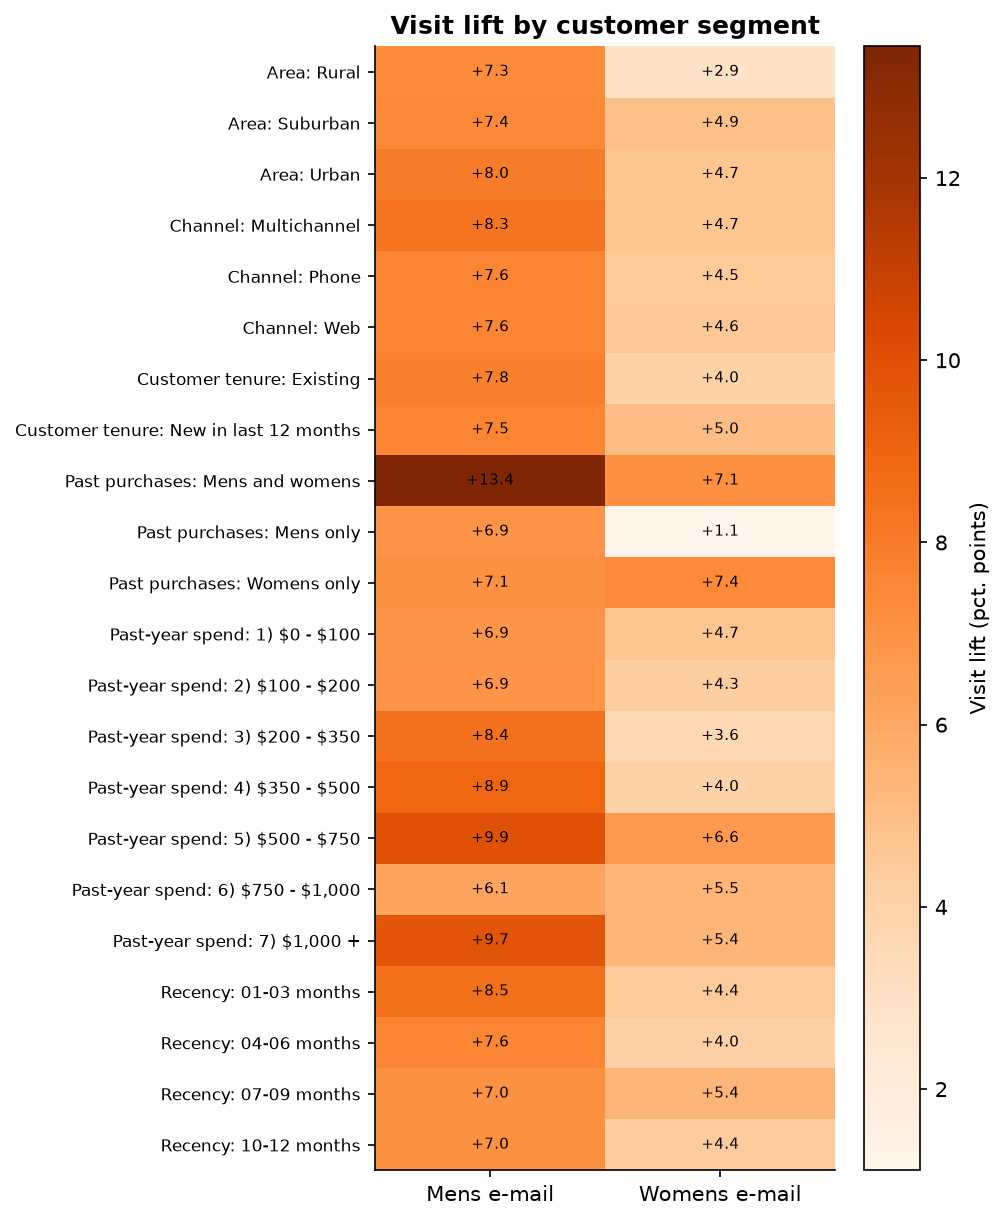

In [11]:
display(Image(filename='reports/figures/03_segment_visit_lift.png'))

## 7. Uplift models and targeting policy
Model choice and threshold come from the validation split; the test split is scored once.

In [12]:
pd.read_csv('reports/tables/qini_scores.csv').pivot_table(index=['arm', 'model'], columns='split', values='qini_coefficient')

split                                    test  validation
arm    model                                             
Mens   Class transformation (logistic) 0.0002      0.0029
       T-learner (LightGBM)            0.0007     -0.0009
Womens Class transformation (logistic) 0.0097      0.0083
       T-learner (LightGBM)            0.0086      0.0039

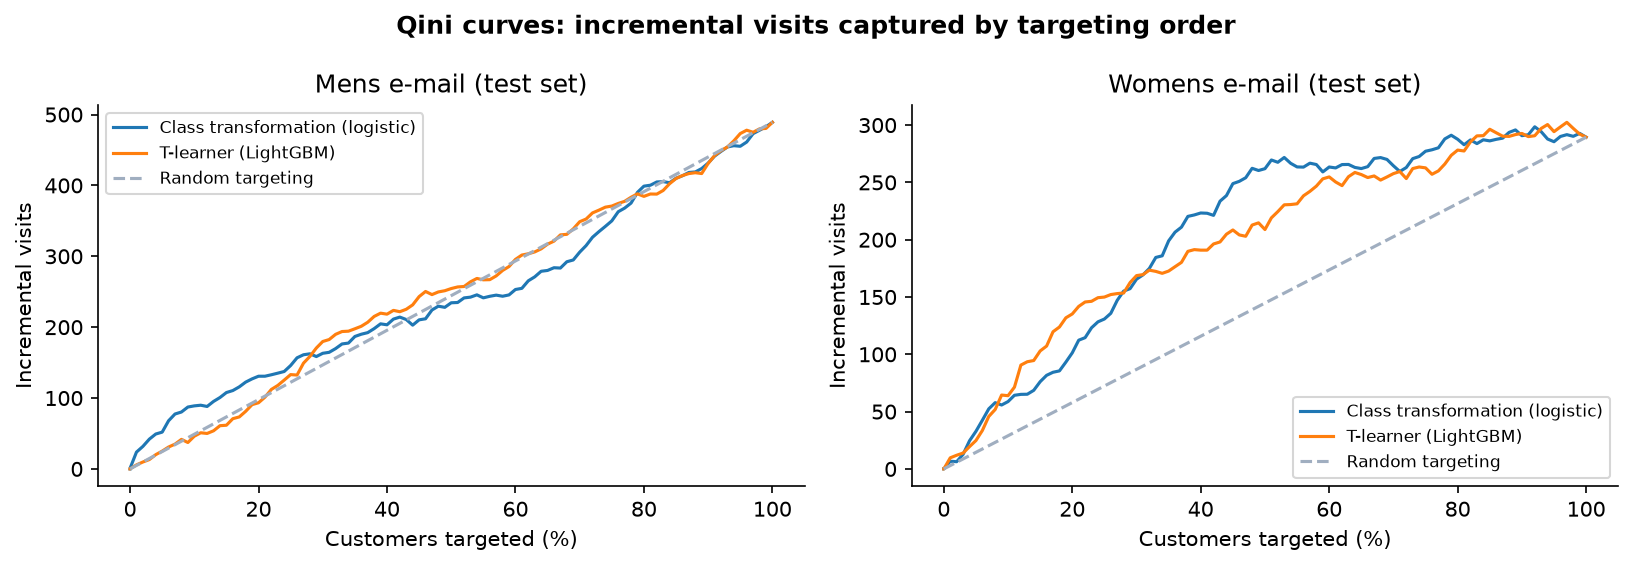

,policy,policy_group,profit_per_customer,ci_low,ci_high,share_mailed
0,No e-mail,Baseline,0.3166,0.2065,0.4402,0.0000
1,Mens e-mail to everyone,Baseline,0.5037,0.3436,0.6981,1.0000
2,Womens e-mail to everyone,Baseline,0.3320,0.1919,0.4887,1.0000
3,Model policy,Model policy,0.4571,0.3074,0.6273,1.0000


In [13]:
display(Image(filename='reports/figures/04_qini_curves.png'))
pd.read_csv('reports/tables/policy_value.csv')

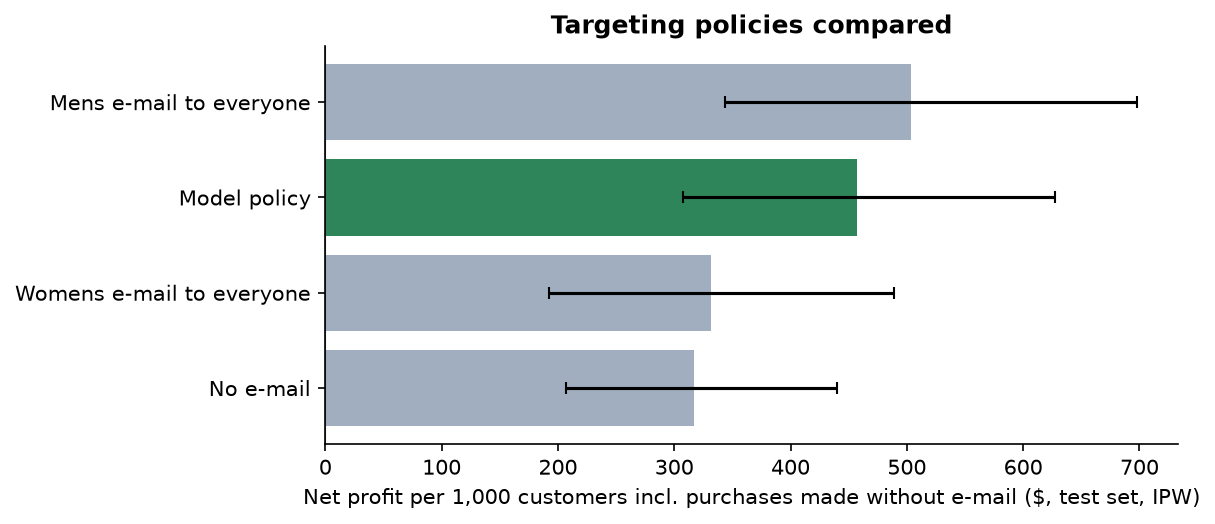

In [14]:
display(Image(filename='reports/figures/05_policy_profit.png'))

## 8. Campaign P&L

In [15]:
pd.read_csv('reports/tables/pnl.csv')

,arm,scenario,incremental_spend_per_customer,gross_profit_per_customer,net_profit_per_customer,net_profit_next_campaign,roi,break_even_cost_per_email
0,Mens,estimate,0.7698,0.3079,0.2079,"20,793.0862",2.0793,0.3079
1,Mens,ci_low,0.4851,0.1941,0.0941,"9,405.5893",0.9406,0.1941
2,Mens,ci_high,1.0545,0.4218,0.3218,"32,180.5832",3.2181,0.4218
3,Womens,estimate,0.4244,0.1698,0.0698,"6,976.4886",0.6976,0.1698
4,Womens,ci_low,0.1690,0.0676,-0.0324,"-3,241.7284",-0.3242,0.0676
5,Womens,ci_high,0.6799,0.2719,0.1719,"17,194.7057",1.7195,0.2719


## 9. Memo

In [16]:
display(Markdown(open('reports/memo.md').read()))

# Memo: e-mail test results and next-campaign decision

**To:** Marketing lead · **From:** Analytics · **Data:** Hillstrom e-mail test, 64,000 customers, 2-week outcomes

**Decision:** Send the **Mens e-mail** next time: each e-mail returns 2.1 times its assumed cost in net profit. Skip uplift targeting for now: on held-out customers it earned less than mailing everyone the Mens e-mail. Revisit it once richer customer features are available.

**What we found**

- **Randomization held.** Arm sizes 21,306 / 21,307 / 21,387 (sample-ratio test p = 0.90); largest covariate imbalance |SMD| = 0.014, under the 0.1 rule of thumb.
- **Both e-mails lifted visits and spend.** Effects with a Holm-adjusted p-value below 0.05 across the 6 tests: Mens visit, Mens conversion, Mens spend, Womens visit, Womens conversion, Womens spend. Effects that do not pass the correction: none.
- **The Mens e-mail earns more.** It added $0.770 of spend per customer (95% CI $0.485 to $1.055) against $0.424 for the Womens e-mail. At a 40% margin and $0.10 per e-mail that is $0.208 net per customer mailed, or $20,793 on a 100,000-customer list ($9,406 at the CI lower bound).
- **Break-even cost.** The Mens e-mail stays profitable up to $0.308 per e-mail at this margin, 3.1 times the assumed cost.
- **Targeting does not beat the best blanket send.** An uplift policy chosen on validation data and scored once on 19,200 held-out customers earns $457 per 1,000 customers, including purchases they would have made anyway (95% CI $307 to $627), versus $504 (95% CI $344 to $698) for 'Mens e-mail to everyone'. Mailing everyone is the better choice on this evidence.
- **CUPED with past-year spend barely helps here** (variance reduction 0.4% for visits, 0.0% for spend).

**Money at stake:** $20,793 expected net profit from the Mens e-mail on a
100,000-customer list, against $6,976 for the Womens e-mail.

**Caveats:** margin (40%) and e-mail cost ($0.10) are assumptions; outcomes
cover two weeks only; segment and model-policy gains are not yet confirmed by a fresh test.
